# Arabica + robusta + chicory (ARC): chicory models

**Assumption:** each "AR a-b" dish is a three-component blend: an arabica–robusta coffee base plus **b % chicory**
(the chemistry checks in `arabica_robusta_models_and_classifier.ipynb`: coffee-oil band falls with b towards the chicory
value, the existing robusta + chicory model reads b, the coffee base sits midway between arabica and robusta).
"AR 100" = coffee base with 0 % chicory. **The 13:30 "AR 50-50" dishes are left out.**

1. Chicory model trained on the ARC dishes alone (nested leave-one-session-out, 3 ARC sessions).
2. The app's existing chicory models applied to the ARC dishes, never trained on them.
3. **One chicory model for all three mixtures** (robusta + chicory, arabica + chicory, ARC), nested leave-one-**day**-out,
   error reported per mixture.
4. Indicative arabica : robusta split of each ARC dish's coffee base (no reference values exist for it).

Outputs: `arc_chicory_models/`.

## 1. Data

In [1]:
import os
import json, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import savgol_filter
from sklearn.cross_decomposition import PLSRegression
from sklearn.cluster import KMeans
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
warnings.filterwarnings("ignore")
BASE = Path(os.environ.get("COFFEE_DATA", "."))
OUT = BASE / "arc_chicory_models"; OUT.mkdir(exist_ok=True)
_ns = {}; exec((BASE / "coffee_app" / "train_app_models.py").read_text().split("fam = {}")[0], _ns)
load, preprocess, COLS = _ns["load"], _ns["preprocess"], _ns["COLS"]
WL = np.array([float(c) for c in COLS]); CHEM = ((WL >= 1650) & (WL <= 1800)) | ((WL >= 2150) & (WL <= 2400))
DAY = {("RBCH", 1): "1 Sep", ("RBCH", 2): "4 Sep", ("RBCH", 3): "8 Sep", ("ABCH", 1): "1 Sep", ("ABCH", 2): "4 Sep",
       ("ABCH", 3): "8 Sep", ("ARC", 1): "4 Sep 12:00", ("ARC", 2): "4 Sep 13:30", ("ARC", 3): "7 Sep"}
DAYKEY = {"4 Sep 12:00": "4 Sep", "4 Sep 13:30": "4 Sep"}

frames = []
for F in ("RBCH", "ABCH"):
    frames.append(load(F).assign(fam=F))
AR = pd.read_csv(BASE / "arabica_robusta_out" / "training_samples.csv")
Dar = AR[(AR.role == "calibration") & ~((AR.day == 2) & (AR.label == "AR[50:50]"))].copy()
Dar["session"] = Dar.day.astype(int); Dar["chicory_pct"] = Dar.robusta_pct      # second number = chicory % (assumption)
frames.append(Dar.assign(fam="ARC"))
D = pd.concat(frames, ignore_index=True)
D["setname"] = [DAY[(f, s)] for f, s in zip(D.fam, D.session)]
D["daykey"] = D.setname.map(lambda s: DAYKEY.get(s, s))
D["dish"] = D.fam + "|" + D.group.astype(str)
Z = preprocess(D[COLS].values); Y = D.chicory_pct.to_numpy(float)
print(D.groupby(["fam", "setname"]).agg(levels=("chicory_pct", lambda v: sorted(set(v))), dishes=("dish", "nunique")).to_string())

                                          levels  dishes
fam  setname                                            
ABCH 1 Sep                                 [0.0]       3
     4 Sep        [10.0, 20.0, 30.0, 40.0, 50.0]      15
     8 Sep         [5.0, 15.0, 25.0, 35.0, 45.0]      15
ARC  4 Sep 12:00              [30.0, 40.0, 50.0]       9
     4 Sep 13:30               [0.0, 10.0, 20.0]       9
     7 Sep         [5.0, 15.0, 25.0, 35.0, 45.0]      15
RBCH 1 Sep                                 [0.0]       3
     4 Sep        [10.0, 20.0, 30.0, 40.0, 50.0]      15
     8 Sep         [5.0, 15.0, 25.0, 35.0, 45.0]      15


## 2. ARC alone: nested leave-one-session-out (from `arabica_robusta_models_excl_1330_5050/`)

In [2]:
ARC_ONLY = pd.read_csv(BASE / "arabica_robusta_models_excl_1330_5050" / "model_summary.csv").rename(columns={"model": "method"})
ARC_ONLY.columns = [c.replace("held out", "held out (% chicory)") for c in ARC_ONLY.columns]
print("Same dishes, same target (the label's second number, read here as chicory %):")
print(ARC_ONLY.round(2).to_string(index=False))
hp = pd.read_csv(BASE / "arabica_robusta_models_excl_1330_5050" / "heldout_predictions.csv")
best = hp[hp.model == ARC_ONLY.method.iloc[0]].groupby(["fold", "label", "y"]).p.mean().round(1)
print(f"\nbest ({ARC_ONLY.method.iloc[0]}), predicted chicory % per dish type on its unseen session:"); print(best.to_string())

Same dishes, same target (the label's second number, read here as chicory %):
                            method  S1 held out (% chicory)  S2 held out (% chicory)  S3 held out (% chicory)  mean      bias S1 / S2
chemistry bands, derivative + PLSR                     1.04                     0.90                     0.88  0.94 -0.3 / -0.3 / 0.4
                        ElasticNet                     1.34                     0.82                     1.56  1.24  -1.1 / 0.5 / 1.2
           first derivative + PLSR                     1.26                     1.65                     1.00  1.30 -0.9 / 1.4 / -0.4
                             Ridge                     1.40                     1.05                     1.48  1.31 -1.1 / -0.5 / 1.1
                               PCR                     1.30                     0.92                     2.07  1.43  -1.1 / 0.4 / 1.7
                      SVR (linear)                     1.62                     1.09                     1.85  1.52  -

## 3. The app's existing chicory models on the ARC dishes (never trained on them)

In [3]:
APPM = json.loads((BASE / "coffee_app" / "models.json").read_text())
lam = np.linspace(-1, 1, len(COLS))
def app_chicory(z, F):
    f = APPM["families"][F]
    if "emsc" in f:
        B = np.column_stack([np.ones_like(lam), f["emsc"]["mean"], f["emsc"]["chicory_direction"], lam, lam ** 2])
        a, b, h, d, e = np.linalg.lstsq(B, z, rcond=None)[0]; z = (z - a - d * lam - e * lam ** 2) / b
    return z @ np.array(f["model"]["w"]) + f["model"]["w0"]
arc = D[D.fam == "ARC"]
dm = pd.DataFrame(Z[arc.index]).groupby(arc.dish.values).mean()
info = arc.groupby("dish").agg(setname=("setname", "first"), label=("label", "first"), y=("chicory_pct", "first"))
T = info.assign(RBCH_model=[app_chicory(z, "RBCH") for z in dm.loc[info.index].values],
                ABCH_model=[app_chicory(z, "ABCH") for z in dm.loc[info.index].values])
rows = []
for s, g in T.groupby("setname"):
    rows.append(dict(scan_set=s, **{m: float(np.sqrt(((g[m] - g.y) ** 2).mean())) for m in ("RBCH_model", "ABCH_model")}))
TRANSFER = pd.DataFrame(rows); TRANSFER.loc[len(TRANSFER)] = dict(scan_set="mean", **TRANSFER[["RBCH_model", "ABCH_model"]].mean())
print("RMSE per dish (% chicory):"); print(TRANSFER.round(2).to_string(index=False))
print("\nper dish type:"); print(T.groupby(["setname", "label"])[["y", "RBCH_model", "ABCH_model"]].mean().round(1).to_string())

RMSE per dish (% chicory):
   scan_set  RBCH_model  ABCH_model
4 Sep 12:00        1.65        8.99
4 Sep 13:30        7.18       13.69
      7 Sep        1.20       11.31
       mean        3.34       11.33

per dish type:
                          y  RBCH_model  ABCH_model
setname     label                                  
4 Sep 12:00 AR[50:50]  50.0        48.5        57.5
            AR[60:40]  40.0        37.8        48.4
            AR[70:30]  30.0        29.0        40.7
4 Sep 13:30 AR100       0.0        -8.4        14.5
            AR[80:20]  20.0        13.5        32.2
            AR[90:10]  10.0         3.5        24.3
7 Sep       AR[55:45]  45.0        44.5        52.8
            AR[65:35]  35.0        34.4        44.1
            AR[75:25]  25.0        24.4        36.4
            AR[85:15]  15.0        14.2        27.7
            AR[95:5]    5.0         4.6        19.3


## 4. One chicory model for all three mixtures: nested leave-one-day-out

Training pools robusta + chicory, arabica + chicory and ARC dishes. Each **day** (1, 4, 7, 8 Sep) is held out in turn, so a
held-out dish's day, white strip and lamp were never seen. Inside each round: trimming refitted on the training days,
super-patches of about 8 patches, setting tuned by leave-one-chicory-level-out with the one-standard-error rule.
Error is reported per mixture and held-out day, then averaged.

In [4]:
def units_fold(train_mask, k=8, trim=10):
    """Trimming reference (PLS, 4 comp.) fitted on the training rows of each mixture; super-patches for all rows."""
    UZ, UM = [], []
    for F, g in D.groupby("fam"):
        idx = g.index.to_numpy(); tr = train_mask[idx]
        ref = PLSRegression(4).fit(Z[idx][tr], Y[idx][tr]); mu = Z[idx][tr].mean(0)
        T_ = (Z[idx] - mu) @ ref.x_rotations_; q = ((Z[idx] - mu - T_ @ ref.x_loadings_.T) ** 2).sum(1)
        keep = pd.Series(q).groupby(g.dish.values).rank(pct=True).to_numpy() <= 1 - trim / 100
        for dname in pd.unique(g.dish):
            ii = idx[(g.dish.values == dname) & keep]
            if len(ii) < k: continue
            n = max(1, len(ii) // k)
            lab = KMeans(n, n_init=5, random_state=0).fit_predict(D.loc[ii, ["patch_row", "patch_col"]].to_numpy(float))
            for c in range(n):
                sel = ii[lab == c]; UZ.append(Z[sel].mean(0))
                UM.append(dict(dish=dname, fam=F, y=Y[sel[0]], daykey=D.daykey[sel[0]], setname=D.setname[sel[0]]))
    return np.array(UZ), pd.DataFrame(UM)

def emsc_basis(X, y):
    m = X.mean(0); yc = y - y.mean(); return m, yc @ (X - m) / (yc @ yc)
def emsc_apply(X, m, k):
    lam_ = np.linspace(-1, 1, X.shape[1]); B = np.column_stack([np.ones_like(lam_), m, k, lam_, lam_ ** 2])
    a, b, h, d, e = np.linalg.lstsq(B, X.T, rcond=None)[0]
    return (X - a[:, None] - np.outer(d, lam_) - np.outer(e, lam_ ** 2)) / b[:, None]
FEAT = {"PLSR": lambda X, tr, y: X, "EMSC + PLSR": None,
        "first derivative + PLSR": lambda X, tr, y: savgol_filter(X, 15, 2, deriv=1, axis=1),
        "chemistry bands, derivative + PLSR": lambda X, tr, y: savgol_filter(X, 15, 2, deriv=1, axis=1)[:, CHEM],
        "linear SVR": lambda X, tr, y: X}
GRID = {"linear SVR": [0.01, 0.1, 1, 10]}
def make(method, prm):
    return make_pipeline(StandardScaler(), SVR(kernel="linear", C=prm)) if method == "linear SVR" else PLSRegression(prm)
def plate_rmse(y, p, g):
    t = pd.DataFrame(dict(g=g, y=y, p=p)).groupby("g")[["y", "p"]].mean(); return float(np.sqrt(((t.p - t.y) ** 2).mean()))
def tune(method, X, y, g):
    rows = []
    for prm in GRID.get(method, list(range(1, 13))):
        f = [plate_rmse(y[b], np.ravel(make(method, prm).fit(X[a], y[a]).predict(X[b])), g[b])
             for a, b in LeaveOneGroupOut().split(X, y, groups=y)]
        rows.append((prm, np.mean(f), np.std(f, ddof=1) / np.sqrt(len(f))))
    T_ = pd.DataFrame(rows, columns=["p", "m", "se"]); b = T_.m.idxmin()
    return T_.p[np.flatnonzero(T_.m.to_numpy() <= T_.m[b] + T_.se[b])[0]]

t0 = time.time(); PRED = []
for held in ["1 Sep", "4 Sep", "7 Sep", "8 Sep"]:
    ZU, UM = units_fold((D.daykey != held).to_numpy())
    tr, te = (UM.daykey != held).to_numpy(), (UM.daykey == held).to_numpy()
    y, g = UM.y.to_numpy(float), UM.dish.to_numpy()
    for method in FEAT:
        if method == "EMSC + PLSR":
            m_, k_ = emsc_basis(ZU[tr], y[tr]); X = emsc_apply(ZU, m_, k_)
        else:
            X = FEAT[method](ZU, tr, y)
        prm = tune(method, X[tr], y[tr], g[tr])
        p = np.ravel(make(method, prm).fit(X[tr], y[tr]).predict(X[te]))
        PRED.append(UM[te].assign(p=p, method=method, held=held, param=prm))
    print(f"{held} held out done ({time.time() - t0:.0f} s)", flush=True)
PRED = pd.concat(PRED, ignore_index=True)
dish = PRED.groupby(["method", "held", "fam", "setname", "dish"], as_index=False).agg(y=("y", "first"), p=("p", "mean"))
per = dish.groupby(["method", "fam", "setname"]).apply(lambda t: np.sqrt(((t.p - t.y) ** 2).mean())).rename("rmsep").reset_index()
UNIV = per.pivot_table(index="method", columns="fam", values="rmsep", aggfunc="mean")[["RBCH", "ABCH", "ARC"]]
UNIV["mean of all"] = per.groupby("method").rmsep.mean()
UNIV = UNIV.sort_values("mean of all")
print("\nplate RMSEP on held-out days (% chicory), averaged over the scan sets of each mixture:")
print(UNIV.round(2).to_string())
print("\nfor reference, mixture-specific models (leave-one-session-out within the mixture): "
      "RBCH 0.79 (PLSR), ABCH 0.78 (EMSC + PLSR), ARC 0.94 (chemistry bands, derivative + PLSR)")
BEST_U = UNIV.index[0]
print(f"\nbest single model: {BEST_U}; per scan set:")
print(per[per.method == BEST_U].round(2).to_string(index=False))
UNIV.to_csv(OUT / "universal_chicory_model.csv"); dish.to_csv(OUT / "universal_heldout_dish_predictions.csv", index=False)

1 Sep held out done (168 s)


4 Sep held out done (197 s)


7 Sep held out done (315 s)


8 Sep held out done (415 s)



plate RMSEP on held-out days (% chicory), averaged over the scan sets of each mixture:
fam                                 RBCH  ABCH   ARC  mean of all
method                                                           
linear SVR                          0.88  1.14  1.02         1.01
EMSC + PLSR                         1.11  1.46  0.76         1.11
first derivative + PLSR             1.37  1.49  0.84         1.23
PLSR                                1.53  1.81  0.74         1.36
chemistry bands, derivative + PLSR  1.80  2.27  1.30         1.79

for reference, mixture-specific models (leave-one-session-out within the mixture): RBCH 0.79 (PLSR), ABCH 0.78 (EMSC + PLSR), ARC 0.94 (chemistry bands, derivative + PLSR)

best single model: linear SVR; per scan set:
    method  fam     setname  rmsep
linear SVR ABCH       1 Sep   0.32
linear SVR ABCH       4 Sep   1.48
linear SVR ABCH       8 Sep   1.62
linear SVR  ARC 4 Sep 12:00   0.84
linear SVR  ARC 4 Sep 13:30   1.09
linear SVR  ARC      

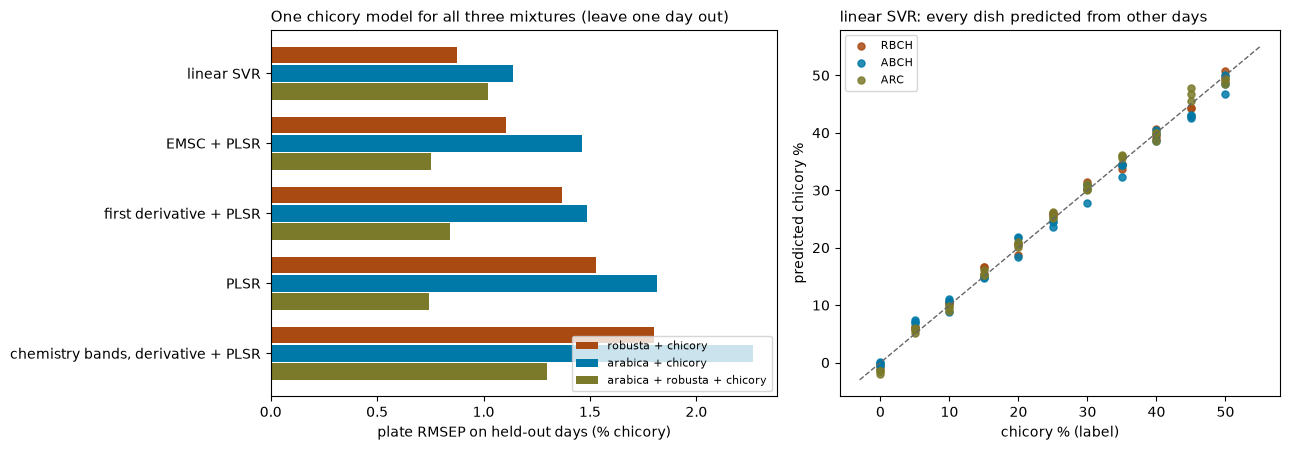

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1.15, 1]))
ax = axs[0]; colors = {"RBCH": "#a84a12", "ABCH": "#0079a8", "ARC": "#7a7a2a"}
yy = np.arange(len(UNIV))
for k, F in enumerate(["RBCH", "ABCH", "ARC"]):
    ax.barh(yy + (k - 1) * .26, UNIV[F], height=.24, color=colors[F], label={"RBCH": "robusta + chicory", "ABCH": "arabica + chicory", "ARC": "arabica + robusta + chicory"}[F])
ax.set_yticks(yy, UNIV.index); ax.invert_yaxis(); ax.set_xlabel("plate RMSEP on held-out days (% chicory)")
ax.set_title("One chicory model for all three mixtures (leave one day out)", loc="left", fontsize=11); ax.legend(fontsize=8, loc="lower right")
ax = axs[1]; b = dish[dish.method == BEST_U]
for F in ["RBCH", "ABCH", "ARC"]:
    q = b[b.fam == F]; ax.scatter(q.y, q.p, s=26, color=colors[F], alpha=.85, label=F)
ax.plot([-3, 55], [-3, 55], ls="--", color="0.4", lw=1); ax.set_xlabel("chicory % (label)"); ax.set_ylabel("predicted chicory %")
ax.set_title(f"{BEST_U}: every dish predicted from other days", loc="left", fontsize=11); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "01_universal_chicory_model.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Indicative coffee-base split of the ARC dishes

The app's coffee-type classifier gives about 0 for robusta-based and 1 for arabica-based blends. Read as the arabica share of
the coffee base, it splits the non-chicory part. **No reference values exist for this split**, so it is indicative only.

In [6]:
C = APPM["classifier"]
score = pd.Series(dm.values @ np.array(C["w"]) + C["w0"], index=dm.index)
hp_best = hp[hp.model == ARC_ONLY.method.iloc[0]].copy()
hp_best["dish"] = "ARC|" + hp_best.group.astype(str)
chic = hp_best.groupby("dish").p.mean()
comp = info.assign(chicory=chic.reindex(info.index), arabica_share=score.reindex(info.index).clip(0, 1))
comp["arabica %"] = (100 - comp.chicory) * comp.arabica_share
comp["robusta %"] = (100 - comp.chicory) * (1 - comp.arabica_share)
COMP = comp.groupby(["setname", "label"])[["y", "chicory", "arabica_share", "arabica %", "robusta %"]].mean().round(1)
COMP = COMP.rename(columns={"y": "chicory label", "chicory": "chicory predicted (unseen session)"})
print(COMP.to_string()); COMP.to_csv(OUT / "arc_composition_indicative.csv")

                       chicory label  chicory predicted (unseen session)  arabica_share  arabica %  robusta %
setname     label                                                                                            
4 Sep 12:00 AR[50:50]           50.0                                49.4            0.5       25.7       24.8
            AR[60:40]           40.0                                39.2            0.5       31.3       29.5
            AR[70:30]           30.0                                30.6            0.4       30.4       39.1
4 Sep 13:30 AR100                0.0                                 0.1            0.6       59.4       40.5
            AR[80:20]           20.0                                20.3            0.5       43.0       36.7
            AR[90:10]           10.0                                 8.6            0.3       28.5       62.9
7 Sep       AR[55:45]           45.0                                45.7            0.6       33.9       20.4
          